In [53]:
import matplotlib.pyplot as plt
import platform
# 그림 속 한글이 네모로 나오지 않게 (운영체제별 글꼴)
fonts = {"Windows": "Malgun Gothic",
"Darwin": "AppleGothic"}
name = fonts.get(platform.system(), "NanumGothic")
plt.rcParams["font.family"] = name
plt.rcParams["axes.unicode_minus"] = False

In [54]:
import pandas as pd
import matplotlib.pyplot as plt
df=pd.read_csv("sales_data.csv")
df.shape

(1030, 14)

In [55]:
before = len(df)
df = df.drop_duplicates()
print(before, "->", len(df))

1030 -> 1004


In [56]:
bad = df["quantity"] > 100
df.loc[bad, "quantity"] = (df.loc[bad, "total_sales"] / df.loc[bad, "unit_price"]).round().astype(int)
diff = (df["total_sales"] - df["quantity"] * df["unit_price"]).abs()
print("고친 줄 :", bad.sum(), " 수량 최대 :", df["quantity"].max(), " 총액 안 맞는 줄 :", (diff > 1).sum())

고친 줄 : 22  수량 최대 : 99  총액 안 맞는 줄 : 0


In [57]:
for col in ["order_date", "shipping_date", "delivery_date"]:
    df[col] = pd.to_datetime(df[col])
df["date_error"] = df["delivery_date"] < df["shipping_date"]
df.to_csv("sales_clean.csv", index=False)
print(df["date_error"].sum(),"건,",df.shape)

147 건, (1004, 15)


평균: 22.05 일
중앙값: 2.0 일
결측치 제외 데이터 개수: 852


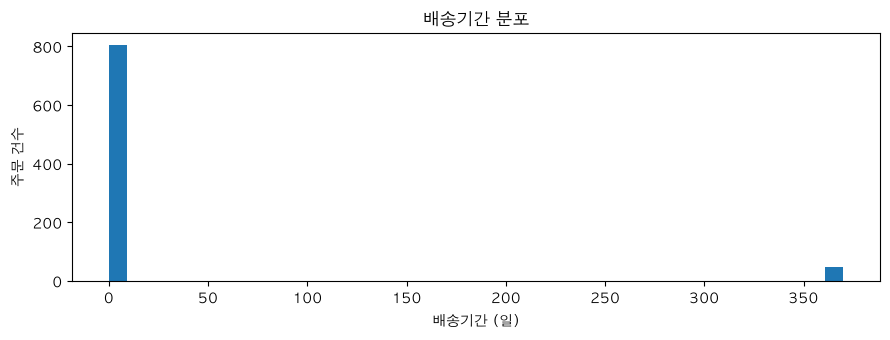

300일 초과: 47


11     365.0
20     369.0
29     365.0
41     368.0
68     364.0
99     367.0
110    365.0
131    369.0
165    368.0
192    367.0
199    364.0
215    368.0
326    367.0
334    368.0
338    367.0
361    367.0
383    370.0
397    366.0
412    368.0
425    370.0
527    365.0
542    365.0
543    365.0
546    367.0
585    364.0
592    368.0
608    365.0
633    370.0
638    365.0
685    366.0
694    369.0
747    364.0
750    367.0
775    366.0
784    368.0
786    364.0
810    365.0
813    367.0
828    366.0
853    367.0
884    366.0
887    369.0
888    365.0
895    364.0
936    368.0
939    369.0
982    366.0
dtype: float64

In [58]:
shipping = df.loc[~df["date_error"]]
days = (shipping["delivery_date"] - shipping["shipping_date"]).dt.days
days = days.dropna()

print("평균:", round(days.mean(), 2), "일")
print("중앙값:", round(days.median(), 2), "일")
print("결측치 제외 데이터 개수:",len(days))
days.plot.hist(bins=40, figsize=(9, 3.5), title="배송기간 분포")
plt.xlabel("배송기간 (일)")
plt.ylabel("주문 건수")
plt.tight_layout()
plt.show()

long_days = days[days > 300]
print("300일 초과:", len(long_days))
long_days

5) 날짜 역전과 결측을 제외한 852건의 평균은 22.05일, 중앙값은 2일이다. 오른쪽 끝의 364~370일짜리 47건이 평균을 끌어올려 둘의 차이가 크다.  
1년인 365일 주변에서만 해당 데이터가 나타나는 것으로 보아 연도 오기이고,
364일이 나오는 경우는 날짜역전으로 결측치 처리하고, 365~370 사이의 데이터는 365를 빼서 데이터로 사용해야한다.


satisfaction
1.0    0.08
2.0    0.12
3.0    0.08
4.0    0.09
5.0    0.07
Name: status, dtype: float64


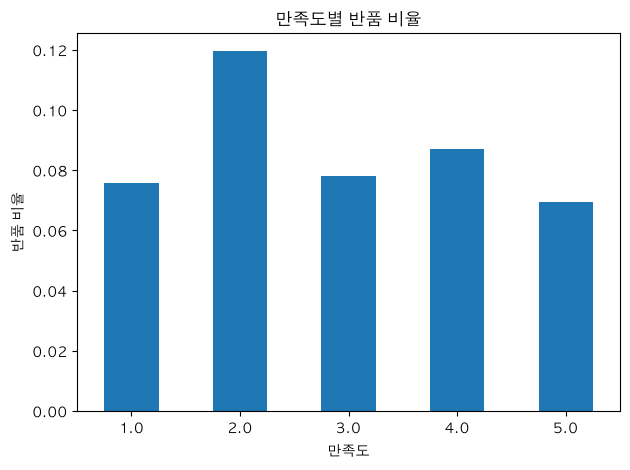

In [59]:
#6) 만족도가 낮을수록 반품이 많은가?

return_rate = (df["status"] == "반품").groupby(df["satisfaction"]).mean()

print(return_rate.round(2))

return_rate.plot.bar(title="만족도별 반품 비율", rot=0)
plt.xlabel("만족도")
plt.ylabel("반품 비율")
plt.tight_layout()
plt.show()

6) 아니다. 4점의 반품 비율이 1점, 3점보다 높기 때문에 만족도가 낮을수록 반품이 많다고 보기는 어렵다.

In [61]:
#7) 카테고리 매출 1위의 이유는 건수· 단가· 수량 중 무엇인가 
by_category = df.groupby("category").agg(
    주문건수=("total_sales", "size"),
    총매출=("total_sales", "sum"),
    평균단가=("unit_price", "mean"),
    평균수량=("quantity", "mean")
)

by_category.round(2)

,주문건수,총매출,평균단가,평균수량
category,,,,
가구,213,2.843337e+09,257322.91,51.04
도서,204,2.453240e+09,238500.64,49.50
식품,210,2.513274e+09,255232.93,47.31
의류,170,2.181904e+09,249447.16,51.61
전자제품,207,2.471628e+09,249651.61,47.96


7) 1위인 가구는 주문 건수가 가장 많고, 평균 단가가 가장 높고 평균 수량도 1위보다 큰 차이가 나지 않기 때문에 총 매출 1위이다.
